# Depressurization of a Nitrogen Storage Cylinder (Section 3.7 model)

**Assumptions (from the text):** gas is spatially lumped, perfect gas with constant specific heats, isentropic flow (no heat transfer), single exit nozzle.

**Stage I – choked nozzle** ($M_e = 1$, $P_e = P_o/\left(\tfrac{\gamma+1}{2}\right)^{\gamma/(\gamma-1)} > P_{atm}$) – Eqs. 3.30 – 3.37  
**Stage II – unchoked nozzle** ($P_e = P_{atm}$, $M_e < 1$) – Eqs. 3.39 – 3.40

Both stages come from one ODE (mass conservation, Eq. 3.26 + 3.28):

$$\frac{dP_o}{dt} = -\,\dot m\,\frac{\gamma P_o}{V\,\rho_o},\qquad \rho_o=\frac{P_o}{R T_o},\quad T_o = T_{o1}\left(\frac{P_o}{P_{o1}}\right)^{(\gamma-1)/\gamma}\ (\text{Eq. 3.38})$$

with $\dot m=\rho_e A_e V_e$. Stage I also has the closed form Eq. 3.36/3.37, used below as a cross-check.

**Run the cells top to bottom. Change inputs only in Cell 1.**

In [67]:
# ============ CELL 1 : INPUTS  (edit these) ============
import numpy as np

# --- Gas: Nitrogen ---
gamma = 1.4
R     = 296.8          # J/(kg K)   (8314.46 / 28.0134)

# --- Reservoir (cylinder) initial state ---
P_o1  = 20e5           # Pa   initial chamber pressure (20 bar)
T_o1  = 300.0          # K    initial gas temperature (assumed = ambient 300 K)

# --- Reservoir volume:  V = pi/4 * D^2 * L ---
D_cyl = 2.54e-2        # m    cylinder inner DIAMETER (2.54 cm).  If 2.54 cm^2 is an AREA, see next line
cyl_area_override = None   # m^2  e.g. 2.54e-4 to give the AREA directly instead of using D_cyl
L_cyl = 1.0            # m    cylinder length   <<< SET THIS (not given in the question)
V_override = 0.001      # m^3  set a number to bypass D_cyl / L_cyl completely

# --- Nozzle exit ---
exit_input = "diameter"    # "diameter"  or  "area"
exit_value = 1e-2       # m if "diameter" (1 cm) ; m^2 if "area"

# --- Ambient ---
P_atm = 1.01325e5      # Pa
T_atm = 300.0          # K  (information only: ambient T does not enter the isentropic equations)

# --- Time ---
t_end = 15.0           # s
n_pts = 3001           # output points

In [68]:
# ============ CELL 2 : DERIVED QUANTITIES ============
A_cyl = cyl_area_override if cyl_area_override is not None else np.pi/4*D_cyl**2
V     = V_override if V_override is not None else A_cyl*L_cyl           # m^3

A_e   = np.pi/4*exit_value**2 if exit_input.lower().startswith("d") else exit_value   # m^2

rho_o1 = P_o1/(R*T_o1)                         # kg/m^3
a_o1   = np.sqrt(gamma*R*T_o1)                 # m/s  speed of sound at initial reservoir conditions
m_o1   = rho_o1*V                              # kg   initial gas mass

PR_crit = ((gamma+1)/2)**(gamma/(gamma-1))     # P_o/P_e at choking  (=1.893 for gamma=1.4)
P_o_crit = PR_crit*P_atm                       # Stage I -> Stage II switch pressure

print(f"Cylinder area      = {A_cyl*1e4:.3f} cm^2")
print(f"Reservoir volume V = {V*1e3:.3f} L   ({V:.4e} m^3)")
print(f"Exit area A_e      = {A_e*1e4:.4f} cm^2")
print(f"Initial gas mass   = {m_o1*1e3:.2f} g,  rho_o1 = {rho_o1:.2f} kg/m^3,  a_o1 = {a_o1:.1f} m/s")
print(f"Choking pressure ratio = {PR_crit:.4f};  Stage I -> II at P_o = {P_o_crit/1e5:.4f} bar")

Cylinder area      = 5.067 cm^2
Reservoir volume V = 1.000 L   (1.0000e-03 m^3)
Exit area A_e      = 0.7854 cm^2
Initial gas mass   = 22.46 g,  rho_o1 = 22.46 kg/m^3,  a_o1 = 353.1 m/s
Choking pressure ratio = 1.8929;  Stage I -> II at P_o = 1.9180 bar


In [69]:
# ============ CELL 3 : MODEL FUNCTIONS ============
def T_o_of(P_o):
    # Eq. 3.38  reservoir stagnation temperature (isentropic)
    return T_o1*(P_o/P_o1)**((gamma-1)/gamma)

def nozzle_state(P_o):
    # Exit conditions for a given chamber pressure P_o (valid for Stage I and Stage II).
    #   Stage I  (P_o >= P_o_crit): P_e = P_o/PR_crit, M_e = 1       (Eq. 3.30)
    #   Stage II (P_o <  P_o_crit): P_e = P_atm,      M_e < 1        (Eq. 3.39)
    P_o = np.maximum(P_o, P_atm)
    T_o = T_o_of(P_o)
    P_e = np.maximum(P_o/PR_crit, P_atm)
    M_e = np.sqrt(np.maximum(2/(gamma-1)*((P_o/P_e)**((gamma-1)/gamma)-1), 0.0))
    T_e = T_o/(1+(gamma-1)/2*M_e**2)
    V_e = M_e*np.sqrt(gamma*R*T_e)                      # same as Eq. 3.29 / 3.31
    rho_e = P_e/(R*T_e)
    mdot = rho_e*A_e*V_e                                # Eq. 3.26
    thrust = mdot*V_e + (P_e-P_atm)*A_e                 # momentum + pressure thrust
    return dict(T_o=T_o, P_e=P_e, M_e=M_e, T_e=T_e, V_e=V_e, rho_e=rho_e, mdot=mdot, thrust=thrust)

def dPo_dt(t, y):
    P_o = max(y[0], P_atm)                              # cannot go below ambient
    rho_o = P_o/(R*T_o_of(P_o))
    mdot = nozzle_state(P_o)["mdot"]
    return [-mdot*gamma*P_o/(V*rho_o)]                  # Eq. 3.26 + 3.28

In [70]:
# ============ CELL 4 : SOLVE (numerical, both stages) ============
from scipy.integrate import solve_ivp

t = np.linspace(0, t_end, n_pts)
sol = solve_ivp(dPo_dt, (0, t_end), [P_o1], t_eval=t, method="LSODA", rtol=1e-10, atol=1e-6)
P_o = np.maximum(sol.y[0], P_atm)
print("solver status:", sol.message)

solver status: The solver successfully reached the end of the integration interval.


In [71]:
# ============ CELL 5 : POST-PROCESS ============
s = nozzle_state(P_o)
T_o, P_e, M_e, V_e, mdot, thrust = s["T_o"], s["P_e"], s["M_e"], s["V_e"], s["mdot"], s["thrust"]
rho_o     = P_o/(R*T_o)
PoPe      = P_o/P_e                       # chamber-to-exit pressure ratio
stage     = np.where(P_o >= P_o_crit, 1, 2)
m_gas     = rho_o*V
_trapz    = getattr(np, "trapezoid", None) or np.trapz   # works on NumPy 1.x and 2.x
impulse   = _trapz(thrust, t)             # N s

# switch time Stage I -> II
idx = np.argmax(P_o < P_o_crit) if (P_o < P_o_crit).any() else None
t_switch = t[idx] if idx is not None else None
# time when chamber essentially reaches ambient
idx_amb = np.argmax(P_o <= P_atm*1.001) if (P_o <= P_atm*1.001).any() else None
t_empty = t[idx_amb] if idx_amb is not None else None

print(f"Stage I -> II switch time : {t_switch if t_switch is None else round(t_switch,4)} s")
print(f"Chamber ~ ambient at      : {t_empty if t_empty is None else round(t_empty,4)} s")
print(f"P_o at t = {t_end:.0f} s        : {P_o[-1]/1e5:.4f} bar")
print(f"Peak thrust (t=0)         : {thrust[0]:.2f} N")
print(f"Initial exit velocity     : {V_e[0]:.1f} m/s")
print(f"Initial mass flow         : {mdot[0]*1e3:.2f} g/s")
print(f"Total impulse             : {impulse:.2f} N s")
print(f"Gas left in cylinder      : {m_gas[-1]*1e3:.2f} g of {m_o1*1e3:.2f} g")

Stage I -> II switch time : 0.125 s
Chamber ~ ambient at      : 0.185 s
P_o at t = 15 s        : 1.0132 bar
Peak thrust (t=0)         : 191.20 N
Initial exit velocity     : 322.3 m/s
Initial mass flow         : 360.45 g/s
Total impulse             : 8.22 N s
Gas left in cylinder      : 2.67 g of 22.46 g


In [72]:
# ============ CELL 6 : RESULTS TABLE (pick your own time stamps) ============
import pandas as pd
t_list = [0, 0.5, 1, 2, 3, 5, 7.5, 10, 12.5, 15]          # s  <- edit
rows = []
for tt in t_list:
    if tt > t_end: continue
    k = np.argmin(abs(t-tt))
    rows.append({"t [s]": t[k], "Stage": stage[k], "Po [bar]": P_o[k]/1e5, "Pe [bar]": P_e[k]/1e5,
                 "Po/Pe": PoPe[k], "Po/Patm": P_o[k]/P_atm, "To [K]": T_o[k], "Me": M_e[k],
                 "Ve [m/s]": V_e[k], "mdot [g/s]": mdot[k]*1e3, "Thrust [N]": thrust[k]})
df = pd.DataFrame(rows)
df.round(4)

,t [s],Stage,Po [bar],Pe [bar],Po/Pe,Po/Patm,To [K],Me,Ve [m/s],mdot [g/s],Thrust [N]
0,0.0,1,20.0000,10.5656,1.8929,19.7385,300.0000,1.0,322.3042,360.4521,191.1995
1,0.5,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
2,1.0,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
3,2.0,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
4,3.0,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
5,5.0,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
6,7.5,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
7,10.0,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
8,12.5,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000
9,15.0,2,1.0132,1.0132,1.0000,1.0000,127.9475,0.0,0.0000,0.0000,0.0000


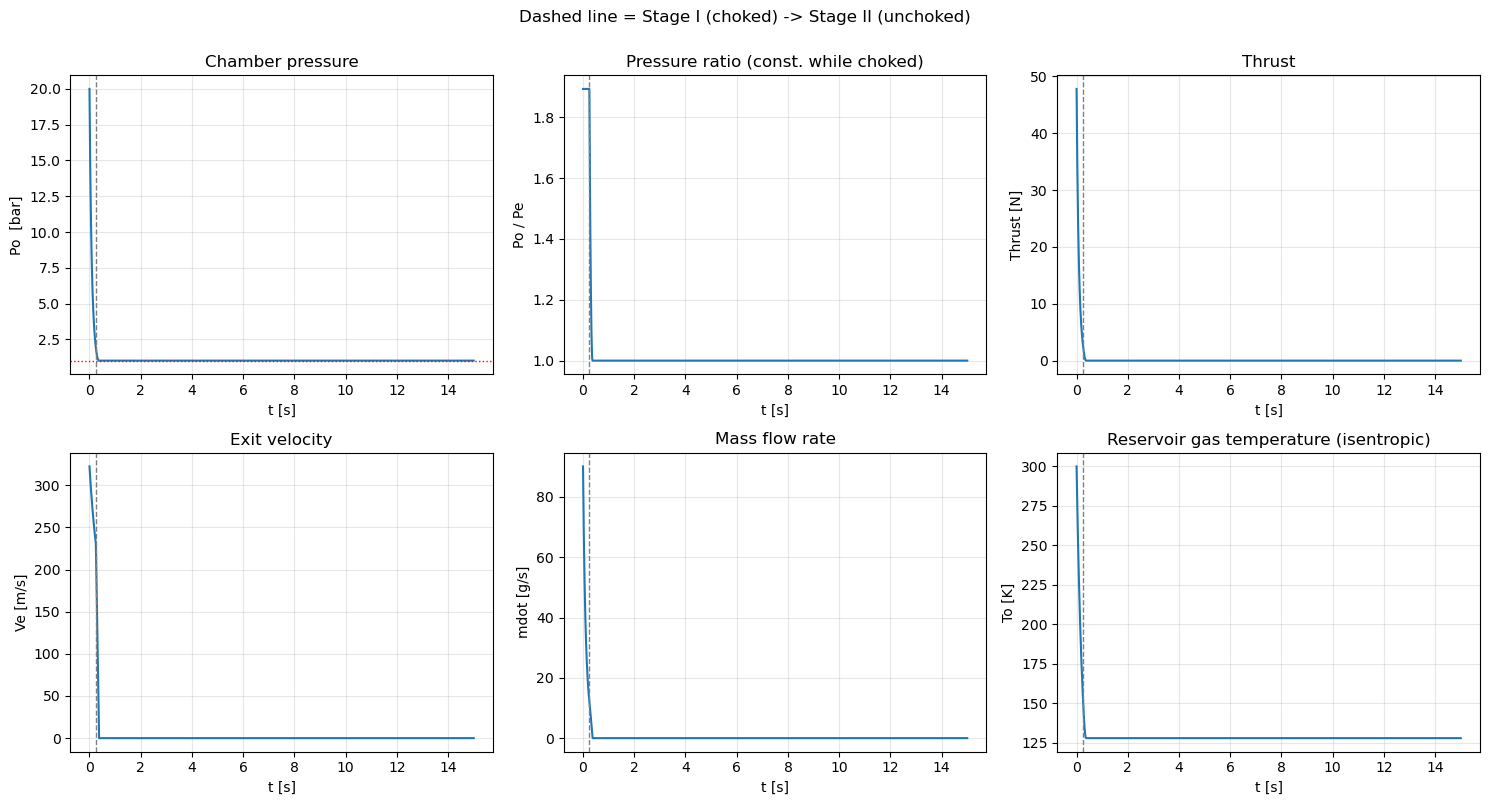

In [40]:
# ============ CELL 7 : PLOTS ============
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
def mark(a):
    if t_switch is not None: a.axvline(t_switch, color="gray", ls="--", lw=1)
    a.grid(alpha=.3); a.set_xlabel("t [s]")

ax[0,0].plot(t, P_o/1e5);  ax[0,0].set_ylabel("Po  [bar]");  ax[0,0].set_title("Chamber pressure"); mark(ax[0,0])
ax[0,0].axhline(P_atm/1e5, color="r", ls=":", lw=1)
ax[0,1].plot(t, PoPe);     ax[0,1].set_ylabel("Po / Pe");    ax[0,1].set_title("Pressure ratio (const. while choked)"); mark(ax[0,1])
ax[0,2].plot(t, thrust);   ax[0,2].set_ylabel("Thrust [N]"); ax[0,2].set_title("Thrust"); mark(ax[0,2])
ax[1,0].plot(t, V_e);      ax[1,0].set_ylabel("Ve [m/s]");   ax[1,0].set_title("Exit velocity"); mark(ax[1,0])
ax[1,1].plot(t, mdot*1e3); ax[1,1].set_ylabel("mdot [g/s]"); ax[1,1].set_title("Mass flow rate"); mark(ax[1,1])
ax[1,2].plot(t, T_o);      ax[1,2].set_ylabel("To [K]");     ax[1,2].set_title("Reservoir gas temperature (isentropic)"); mark(ax[1,2])
fig.suptitle("Dashed line = Stage I (choked) -> Stage II (unchoked)", y=1.0)
plt.tight_layout(); plt.show()

In [41]:
# ============ CELL 8 : CHECK vs CLOSED FORM (Stage I, Eqs. 3.34 - 3.37) ============
b  = (1-gamma)/(2*gamma)
C1 = -(gamma*A_e/V)*(2/(gamma+1))**(1/(gamma-1))*np.sqrt(2*gamma*P_o1**(1/gamma)/((gamma+1)*rho_o1))

def t_stageI(Po):                                    # Eq. 3.37
    return (Po**b - P_o1**b)/(b*C1)

t_sw_closed = t_stageI(P_o_crit)
print(f"Closed-form Stage I duration (Eq. 3.37): {t_sw_closed:.5f} s")
print(f"Numerical switch time                  : {t_switch if t_switch is None else round(t_switch,5)} s")

mask = t <= t_sw_closed
Po_closed = (P_o1**b + b*C1*t[mask])**(1/b)          # Eq. 3.36
print(f"max |Po_numeric - Po_closed| in Stage I : {np.max(abs(P_o[mask]-Po_closed))/1e5:.2e} bar")

# Eq. 3.37a form (uses a_o1) - should match Eq. 3.37
t_a = (V/(A_e*a_o1))*(2/(gamma-1))*((gamma+1)/2)**((gamma+1)/(2*(gamma-1)))*((P_o_crit/P_o1)**((1-gamma)/(2*gamma)) - 1)
print(f"Eq. 3.37a form                          : {t_a:.5f} s")

Closed-form Stage I duration (Eq. 3.37): 0.24791 s
Numerical switch time                  : 0.25 s
max |Po_numeric - Po_closed| in Stage I : 1.08e-09 bar
Eq. 3.37a form                          : 0.24791 s


In [42]:
# ============ CELL 9 : EXPORT (optional) ============
out = pd.DataFrame({"t_s": t, "Po_bar": P_o/1e5, "Pe_bar": P_e/1e5, "Po_over_Pe": PoPe, "To_K": T_o,
                    "Me": M_e, "Ve_mps": V_e, "mdot_kgps": mdot, "Thrust_N": thrust, "Stage": stage})
out.to_csv("depressurization_results.csv", index=False)
print("saved depressurization_results.csv")

saved depressurization_results.csv
